# Proyek UAS Keamanan Data (DSF01)
## Deteksi Phishing URL dengan Machine Learning

**Kelompok 1:** Stevanus, Alra Nava Ratna Mandala

**Tujuan:** mengklasifikasikan URL sebagai *legitimate* atau *phishing* hanya dari teks URL (tanpa mengunjungi situs), sebagai penyaring dini untuk melindungi **Confidentiality** (kredensial dan data pribadi) dan **Integrity** (alur transaksi dan sesi pengguna).

**Alur kerja:** data → fitur → audit bias → split per domain → benchmark & tuning model → pemilihan ambang → evaluasi akhir → ablasi & analisis error → penyimpanan model.

> **Cara menjalankan:** letakkan `URL dataset.csv` dan `Phishing URLs.csv` di folder yang sama dengan notebook, lalu *Run All* (sekitar 4–5 menit di CPU biasa).

## 1. Impor & Konfigurasi

In [1]:
# Impor pustaka & konfigurasi (SEED tetap agar hasil dapat direproduksi; target recall 98%)
import os, re, math, time, warnings, joblib
from collections import Counter
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, classification_report,
                             precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

SEED = 42
TARGET_RECALL = 0.98     # target operasional: minimal 98% phishing tertangkap
np.random.seed(SEED)
print("Pustaka siap. SEED =", SEED, "| TARGET_RECALL =", TARGET_RECALL)

Pustaka siap. SEED = 42 | TARGET_RECALL = 0.98


## 2. Memuat & Membersihkan Data

In [2]:
# Muat kedua CSV, buang label konflik & duplikat; seluruh data dipakai
def cari_file(nama):
    kandidat = [nama, f"Phishing URL dataset/{nama}", f"../Dataset/Phishing URL dataset/{nama}",
                f"/content/{nama}", f"/content/Phishing URL dataset/{nama}"]
    for k in kandidat:
        if os.path.exists(k):
            return k
    raise FileNotFoundError(f"{nama} tidak ditemukan. Letakkan CSV di folder yang sama dengan notebook.")

df_a = pd.read_csv(cari_file("URL dataset.csv"))
df_b = pd.read_csv(cari_file("Phishing URLs.csv"))
df_a.columns = df_b.columns = ["url", "type"]
print("df_a:", df_a.shape, "| df_b:", df_b.shape)

df = pd.concat([df_a, df_b], ignore_index=True)
df["url"] = df["url"].astype(str).str.strip()
df["type"] = df["type"].astype(str).str.lower().str.strip()
print("\nNilai label mentah:\n", df["type"].value_counts().to_string())

df = df[df["type"].isin(["legitimate", "phishing"])].copy()

# URL yang sama dengan label berbeda = label konflik -> dibuang (tidak bisa dipercaya)
jml_label = df.groupby("url")["type"].nunique()
url_konflik = jml_label[jml_label > 1].index
print(f"\nURL dengan label konflik : {len(url_konflik)}")
df = df[~df["url"].isin(url_konflik)]

n_awal = len(df)
df = df.drop_duplicates("url").reset_index(drop=True)
df["y"] = (df["type"] == "phishing").astype(int)
print(f"Baris sebelum dedup: {n_awal} | sesudah: {len(df)}")
print("\nDistribusi kelas (seluruh data dipakai):")
print(df["type"].value_counts().to_string())
print(f"Proporsi phishing: {df['y'].mean():.1%}")

df_a: (450176, 2) | df_b: (54807, 2)

Nilai label mentah:
 type
legitimate    345738
phishing      159245

URL dengan label konflik : 0
Baris sebelum dedup: 504983 | sesudah: 504932

Distribusi kelas (seluruh data dipakai):
type
legitimate    345738
phishing      159194
Proporsi phishing: 31.5%


**Interpretasi:** 504.932 URL unik dengan 31,5% phishing, dan tidak ada URL berlabel bertentangan. Kelas tidak seimbang, sehingga evaluasi memakai **PR-AUC, recall, dan precision**, bukan accuracy.

## 3. Eksplorasi Data

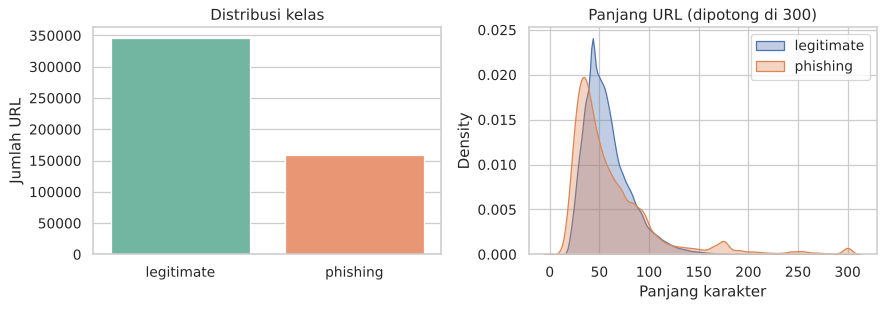

In [3]:
# Distribusi kelas dan panjang URL
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.countplot(data=df, x="type", hue="type", palette="Set2", legend=False, ax=ax[0])
ax[0].set_title("Distribusi kelas"); ax[0].set_xlabel(""); ax[0].set_ylabel("Jumlah URL")

panjang = df["url"].str.len().clip(upper=300)
for lbl, nama in [(0, "legitimate"), (1, "phishing")]:
    sns.kdeplot(panjang[df["y"] == lbl], ax=ax[1], label=nama, fill=True, alpha=.35)
ax[1].set_title("Panjang URL (dipotong di 300)"); ax[1].set_xlabel("Panjang karakter"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi:** Panjang URL kedua kelas saling tumpang tindih (median 53 karakter untuk legitimate dan 49 untuk phishing), sehingga panjang saja bukan pembeda yang kuat. Model perlu fitur yang lebih kaya.

## 4. Ekstraksi Fitur

In [4]:
# Ekstraksi 31 fitur dari teks URL (tanpa mengakses situs target)
KW = ["login", "signin", "verify", "secure", "account", "update", "bank", "paypal", "confirm",
      "password", "webscr", "ebay", "free", "bonus", "support", "wallet"]
KW_RE = re.compile("|".join(KW), re.I)
IP_RE = re.compile(r"^\d{1,3}(\.\d{1,3}){3}$")
SHORT_RE = re.compile(r"(^|\.)(bit\.ly|goo\.gl|tinyurl\.com|ow\.ly|t\.co|is\.gd|buff\.ly|adf\.ly|cutt\.ly|rb\.gy)$")
EXT_RE = re.compile(r"\.(php|exe|zip|js|asp|aspx|jsp|cgi)$", re.I)

FITUR = ["url_len", "host_len", "path_len", "query_len", "host_dots", "host_hyphens", "host_digits",
         "n_subdomain", "tld_len", "host_is_ip", "host_entropy", "url_entropy", "longest_label",
         "path_depth", "n_slash", "n_question", "n_equal", "n_and", "n_percent", "n_at",
         "n_underscore", "n_digits", "digit_ratio", "special_ratio", "n_keyword", "has_shortener",
         "has_punycode", "ext_risky", "double_slash_path", "has_https", "has_www"]
SHORTCUT = ["has_https", "has_www"]   # fitur yang dicurigai sebagai "jalan pintas" dataset (diaudit di bawah)

def entropy(s):
    if not s:
        return 0.0
    n = len(s)
    return -sum(v / n * math.log2(v / n) for v in Counter(s).values())

def host_dari(u):
    try:
        p = urlparse(u if "://" in u else "http://" + u)
        return p, (p.hostname or "")
    except ValueError:
        return urlparse("http://x"), ""

def ekstrak_satu(u):
    p, host = host_dari(u)
    path, query = p.path, p.query
    labels = host.split(".") if host else []
    is_ip = 1 if IP_RE.match(host) else 0
    n = max(len(u), 1)
    dig = sum(c.isdigit() for c in u)
    let = sum(c.isalpha() for c in u)
    return [
        len(u), len(host), len(path), len(query),
        host.count("."), host.count("-"), sum(c.isdigit() for c in host),
        0 if is_ip else max(len(labels) - 2, 0),
        0 if (is_ip or not labels) else len(labels[-1]),
        is_ip, entropy(host), entropy(u),
        max((len(l) for l in labels), default=0),
        path.count("/"), u.count("/"), u.count("?"), u.count("="), u.count("&"),
        u.count("%"), u.count("@"), u.count("_"),
        dig, dig / n, (n - dig - let) / n,
        len(KW_RE.findall(u)),
        1 if SHORT_RE.search(host) else 0,
        1 if "xn--" in host else 0,
        1 if EXT_RE.search(path) else 0,
        1 if "//" in path else 0,
        1 if u.lower().startswith("https") else 0,
        1 if host.startswith("www.") else 0,
    ]

def ekstrak_fitur(urls, chunk=50000):
    bagian = []
    for i in range(0, len(urls), chunk):
        arr = [ekstrak_satu(u) for u in urls[i:i + chunk]]
        bagian.append(pd.DataFrame(arr, columns=FITUR, dtype="float32"))
    out = pd.concat(bagian, ignore_index=True)
    return out

t0 = time.time()
X = ekstrak_fitur(df["url"].tolist())
y = df["y"].values
print(f"Ekstraksi {X.shape[1]} fitur untuk {len(X):,} URL selesai dalam {time.time()-t0:.0f} detik")
print("Ekstraksi murni dari teks URL: tidak ada koneksi ke situs target (aman).")
display(X.head(3).T.round(2))

Ekstraksi 31 fitur untuk 504,932 URL selesai dalam 15 detik
Ekstraksi murni dari teks URL: tidak ada koneksi ke situs target (aman).
                       0      1      2
url_len            22.00  23.00  24.00
host_len           14.00  15.00  16.00
path_len            0.00   0.00   0.00
query_len           0.00   0.00   0.00
host_dots           2.00   2.00   2.00
host_hyphens        0.00   0.00   0.00
host_digits         0.00   0.00   0.00
n_subdomain         1.00   1.00   1.00
tld_len             3.00   3.00   3.00
host_is_ip          0.00   0.00   0.00
host_entropy        2.84   3.19   3.16
url_entropy         3.66   3.76   3.86
longest_label       6.00   7.00   8.00
path_depth          0.00   0.00   0.00
n_slash             2.00   2.00   2.00
n_question          0.00   0.00   0.00
n_equal             0.00   0.00   0.00
n_and               0.00   0.00   0.00
n_percent           0.00   0.00   0.00
n_at                0.00   0.00   0.00
n_underscore        0.00   0.00   0.00
n_digits 

**Interpretasi:** Ada 31 fitur dalam lima kelompok: ukuran (URL, host, path, query), struktur host (titik, tanda hubung, subdomain, TLD, IP, entropi), karakter khusus, kata sensitif/ekstensi berisiko, dan indikator skema/`www`. Semuanya dihitung dari teks URL saja, sehingga aman dan cepat.

## 5. Audit Bias Dataset

Rata-rata (proporsi URL) per kelas:
            has_https  has_www
kelas                         
legitimate      1.000    0.998
phishing        0.349    0.096

PR-AUC model yang HANYA memakai ['has_https', 'has_www']: 0.989
(acuan acak = proporsi phishing = 0.315)


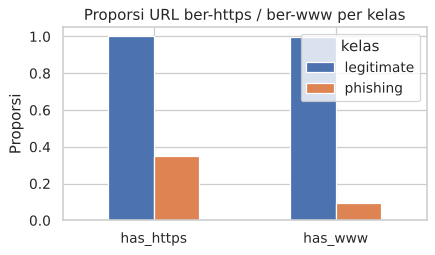

In [5]:
# Audit bias: apakah fitur sepele (https/www) terlalu membedakan kelas?
audit = X[SHORTCUT].assign(kelas=df["type"].values).groupby("kelas")[SHORTCUT].mean().round(3)
print("Rata-rata (proporsi URL) per kelas:")
display(audit)

# Seberapa jauh dua fitur sepele ini saja bisa memisahkan kelas? (PR-AUC pada seluruh data, hanya indikasi)
g = HistGradientBoostingClassifier(max_iter=50, random_state=SEED).fit(X[SHORTCUT], y)
print(f"\nPR-AUC model yang HANYA memakai {SHORTCUT}: {average_precision_score(y, g.predict_proba(X[SHORTCUT])[:,1]):.3f}")
print(f"(acuan acak = proporsi phishing = {y.mean():.3f})")

audit.T.plot(kind="bar", figsize=(5, 3), rot=0, title="Proporsi URL ber-https / ber-www per kelas")
plt.ylabel("Proporsi"); plt.tight_layout(); plt.show()

**Interpretasi:** URL legitimate hampir semuanya memakai `https` (100%) dan `www` (99,8%), sedangkan phishing jauh lebih jarang (34,9% dan 9,6%). Model yang hanya memakai dua fitur itu sudah mencapai PR-AUC 0,989. Ini ciri dataset yang berasal dari dua sumber berbeda, sehingga skor tinggi di dataset ini **tidak otomatis berarti kemampuan mendeteksi phishing secara umum**. Ketergantungan ini diukur pada bagian ablasi.

## 6. Pembagian Data per Domain

In [6]:
# Split 80/20 per domain agar URL satu domain tidak terbagi ke train dan test
SLD = {"co", "com", "org", "net", "gov", "edu", "ac", "or", "go", "ne"}
def domain_daftar(host):
    if not host or IP_RE.match(host):
        return host
    p = host.split(".")
    if len(p) >= 3 and len(p[-1]) == 2 and p[-2] in SLD:
        return ".".join(p[-3:])
    return ".".join(p[-2:]) if len(p) >= 2 else host

groups = np.array([domain_daftar(host_dari(u)[1]) for u in df["url"]])
print("Jumlah domain unik:", len(set(groups)))

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_tr, idx_te = next(gss.split(X, y, groups))
X_tr, X_te = X.iloc[idx_tr].reset_index(drop=True), X.iloc[idx_te].reset_index(drop=True)
y_tr, y_te = y[idx_tr], y[idx_te]
g_tr = groups[idx_tr]
u_tr, u_te = df["url"].values[idx_tr], df["url"].values[idx_te]

print(f"Train: {len(X_tr):,} ({y_tr.mean():.1%} phishing) | Test: {len(X_te):,} ({y_te.mean():.1%} phishing)")
print("Domain yang muncul di train DAN test :", len(set(g_tr) & set(groups[idx_te])), "(harus 0 -> tidak ada kebocoran domain)")

Jumlah domain unik: 141659
Train: 408,901 (33.1% phishing) | Test: 96,031 (25.0% phishing)
Domain yang muncul di train DAN test : 0 (harus 0 -> tidak ada kebocoran domain)


**Interpretasi:** Train berisi 408.901 URL (33,1% phishing) dan test 96.031 URL (25,0% phishing). Tidak ada domain yang muncul di kedua sisi, sehingga tidak ada kebocoran antar-domain. Proporsi phishing berbeda sedikit karena pembagian dilakukan per domain, bukan per baris.

## 7. Benchmark Model (Cross-Validation)

In [7]:
# Bandingkan model dengan GroupKFold (3 lipatan); metrik utama PR-AUC
rng = np.random.RandomState(SEED)
sub = rng.choice(len(X_tr), 100000, replace=False)
Xs, ys, gs, us = X_tr.iloc[sub].reset_index(drop=True), y_tr[sub], g_tr[sub], u_tr[sub]
gkf = GroupKFold(n_splits=3)
lipatan = list(gkf.split(Xs, ys, gs))

kandidat = {
    "Logistic Regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Extra Trees": lambda: ExtraTreesClassifier(n_estimators=100, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": lambda: HistGradientBoostingClassifier(max_iter=150, early_stopping=False, random_state=SEED),
}

def metrik_lipatan(yt, pr):
    pred = (pr >= 0.5).astype(int)
    return [average_precision_score(yt, pr), roc_auc_score(yt, pr), f1_score(yt, pred), recall_score(yt, pred)]

baris = []
for nama, buat in kandidat.items():
    skor, t0 = [], time.time()
    for a, b in lipatan:
        m = buat().fit(Xs.iloc[a], ys[a])
        skor.append(metrik_lipatan(ys[b], m.predict_proba(Xs.iloc[b])[:, 1]))
    s = np.array(skor)
    baris.append([nama, *s.mean(0), s[:, 0].std(), time.time() - t0])
    print("selesai:", nama)

# Pembanding berbasis teks mentah: TF-IDF n-gram karakter + Logistic Regression
skor, t0 = [], time.time()
for a, b in lipatan:
    v = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), max_features=150000, sublinear_tf=True, dtype=np.float32)
    A = v.fit_transform(us[a]); B = v.transform(us[b])
    m = LogisticRegression(max_iter=300, C=10, class_weight="balanced").fit(A, ys[a])
    skor.append(metrik_lipatan(ys[b], m.predict_proba(B)[:, 1]))
s = np.array(skor)
baris.append(["TF-IDF karakter + LogReg", *s.mean(0), s[:, 0].std(), time.time() - t0])

cv_tabel = pd.DataFrame(baris, columns=["Model", "PR-AUC", "ROC-AUC", "F1@0.5", "Recall@0.5", "Std PR-AUC", "Waktu (dtk)"]).sort_values("PR-AUC", ascending=False)
display(cv_tabel.round(4).reset_index(drop=True))

selesai: Logistic Regression
selesai: Random Forest
selesai: Extra Trees
selesai: HistGradientBoosting
                      Model  PR-AUC  ROC-AUC  F1@0.5  Recall@0.5  Std PR-AUC  Waktu (dtk)
0  TF-IDF karakter + LogReg  0.9982   0.9986  0.9909      0.9871      0.0004      32.8892
1      HistGradientBoosting  0.9975   0.9980  0.9910      0.9871      0.0005       6.1611
2               Extra Trees  0.9974   0.9979  0.9911      0.9875      0.0004       9.3212
3             Random Forest  0.9972   0.9978  0.9910      0.9878      0.0005      17.4121
4       Logistic Regression  0.9957   0.9964  0.9831      0.9722      0.0005       0.3978


**Interpretasi:** Empat model teratas hampir setara (PR-AUC 0,997–0,998, selisih dalam kisaran deviasi antar-lipatan). **HistGradientBoosting** dipilih karena cepat (±6 detik vs ±33 detik untuk TF-IDF), berukuran kecil, dan mudah dijelaskan lewat fitur.

## 8. Tuning Hyperparameter

In [8]:
# Tuning HistGradientBoosting dengan RandomizedSearchCV + GroupKFold
ruang = {
    "learning_rate": [0.05, 0.1, 0.2],
    "max_leaf_nodes": [31, 63, 127],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0],
    "max_iter": [150, 300],
}
t0 = time.time()
cari = RandomizedSearchCV(
    HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),
    ruang, n_iter=8, scoring="average_precision", cv=lipatan, random_state=SEED, n_jobs=1, refit=False)
cari.fit(Xs, ys)
BEST = cari.best_params_
print(f"Tuning selesai ({time.time()-t0:.0f} dtk)")
print("Parameter terbaik:", BEST)
print(f"PR-AUC CV terbaik: {cari.best_score_:.4f}")
hasil_cv = pd.DataFrame(cari.cv_results_)[["param_learning_rate", "param_max_leaf_nodes", "param_min_samples_leaf",
                                          "param_l2_regularization", "param_max_iter", "mean_test_score"]]
display(hasil_cv.sort_values("mean_test_score", ascending=False).round(4).reset_index(drop=True))

Tuning selesai (89 dtk)
Parameter terbaik: {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'max_iter': 150, 'learning_rate': 0.05, 'l2_regularization': 0.1}
PR-AUC CV terbaik: 0.9976
   param_learning_rate  param_max_leaf_nodes  param_min_samples_leaf  param_l2_regularization  param_max_iter  mean_test_score
0                 0.05                    31                      50                      0.1             150           0.9976
1                 0.05                    31                      50                      1.0             150           0.9976
2                 0.10                    63                     100                      1.0             150           0.9975
3                 0.10                    31                     100                      0.0             300           0.9974
4                 0.20                    63                      50                      0.1             150           0.9972
5                 0.20                    31            

**Interpretasi:** Seluruh konfigurasi menghasilkan PR-AUC 0,997 dengan selisih sangat kecil. Model sudah jenuh: batas performa ditentukan oleh **data dan fitur**, bukan hyperparameter.

## 9. Pemilihan Ambang (Threshold)

(24 dtk) Ambang terpilih = 0.880  -> pada OOF: recall 0.981, precision 0.997


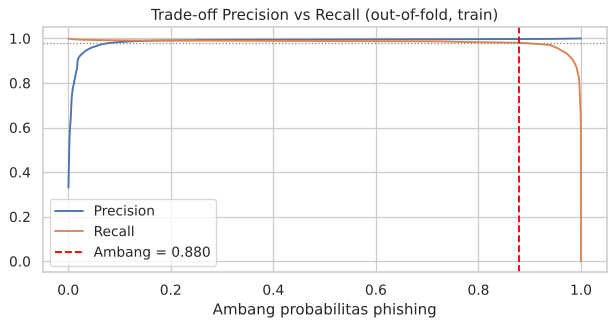

In [9]:
# Pilih ambang dari prediksi out-of-fold agar recall memenuhi target
def buat_final():
    return HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **BEST)

t0 = time.time()
oof = cross_val_predict(buat_final(), X_tr, y_tr, groups=g_tr, cv=GroupKFold(n_splits=3), method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
THR = float(thr[ok[-1]])           # ambang TERTINGGI yang masih memenuhi target recall
idx = ok[-1]
print(f"({time.time()-t0:.0f} dtk) Ambang terpilih = {THR:.3f}  -> pada OOF: recall {rec[idx]:.3f}, precision {prec[idx]:.3f}")

plt.figure(figsize=(7, 3.8))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(THR, color="red", ls="--", label=f"Ambang = {THR:.3f}")
plt.axhline(TARGET_RECALL, color="gray", ls=":", lw=1)
plt.xlabel("Ambang probabilitas phishing"); plt.title("Trade-off Precision vs Recall (out-of-fold, train)")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretasi:** Karena phishing yang lolos (*false negative*) paling berbahaya, ambang dipilih sebagai nilai tertinggi yang masih memenuhi target recall 98%. Hasilnya 0,88: pada data out-of-fold recall 0,981 dan precision 0,997. Test set tidak dipakai pada langkah ini.

## 10. Evaluasi Akhir pada Test Set

Model final dilatih (11 dtk)

             Ambang  PR-AUC  ROC-AUC  Precision  Recall      F1
0     0.50 (bawaan)  0.9966   0.9976     0.9939  0.9833  0.9886
1  0.880 (terpilih)  0.9966   0.9976     0.9975  0.9773  0.9873

Laporan klasifikasi (ambang 0.880):
              precision    recall  f1-score   support

  Legitimate      0.992     0.999     0.996     72029
    Phishing      0.997     0.977     0.987     24002

    accuracy                          0.994     96031
   macro avg      0.995     0.988     0.992     96031
weighted avg      0.994     0.994     0.994     96031



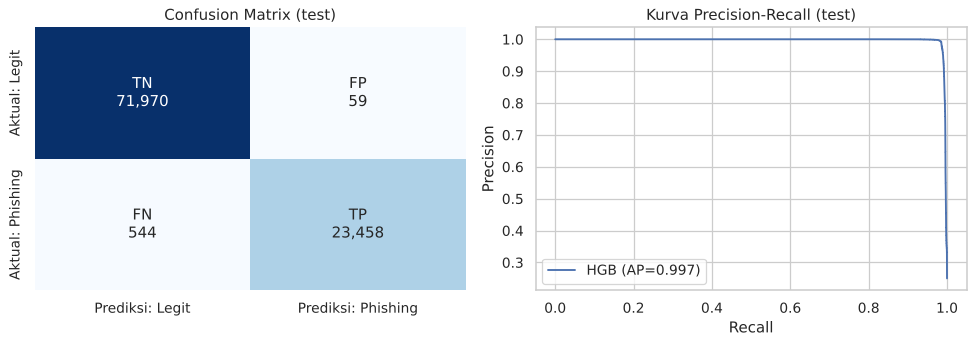

In [10]:
# Evaluasi akhir pada test set (dilakukan sekali saja)
def ringkas(nama, y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Ambang": nama, "PR-AUC": average_precision_score(y_true, proba), "ROC-AUC": roc_auc_score(y_true, proba),
            "Precision": precision_score(y_true, pred), "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred)}

t0 = time.time()
final = buat_final().fit(X_tr, y_tr)
p_final = final.predict_proba(X_te)[:, 1]
print(f"Model final dilatih ({time.time()-t0:.0f} dtk)\n")

tabel_test = pd.DataFrame([ringkas("0.50 (bawaan)", y_te, p_final, 0.5),
                           ringkas(f"{THR:.3f} (terpilih)", y_te, p_final, THR)])
display(tabel_test.round(4))

pred_final = (p_final >= THR).astype(int)
print(f"\nLaporan klasifikasi (ambang {THR:.3f}):")
print(classification_report(y_te, pred_final, target_names=["Legitimate", "Phishing"], digits=3))

cm = confusion_matrix(y_te, pred_final)
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lab = np.array([[f"TN\n{tn:,}", f"FP\n{fp:,}"], [f"FN\n{fn:,}", f"TP\n{tp:,}"]])
sns.heatmap(cm, annot=lab, fmt="", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Prediksi: Legit", "Prediksi: Phishing"], yticklabels=["Aktual: Legit", "Aktual: Phishing"])
ax[0].set_title("Confusion Matrix (test)")
p_, r_, _ = precision_recall_curve(y_te, p_final)
ax[1].plot(r_, p_, label=f"HGB (AP={average_precision_score(y_te, p_final):.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Kurva Precision-Recall (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi:** Pada ambang 0,88: precision 0,997, recall 0,977, F1 0,987 (PR-AUC 0,997). Dari 24.002 phishing, 544 lolos; dari 72.029 URL aman, 59 terblokir. Recall sedikit di bawah target 0,98 karena test berisi domain yang tidak pernah dilihat saat pemilihan ambang; selisih sekecil ini wajar.

## 11. Precision pada Prevalensi Rendah

In [11]:
# Precision pada berbagai prevalensi phishing (kondisi dunia nyata)
tpr = tp / (tp + fn); fpr = fp / (fp + tn)
print(f"Pada ambang {THR:.3f}: TPR (recall) = {tpr:.3f} | FPR = {fpr:.3f}\n")
baris = []
for prev in [0.5, 0.3, 0.1, 0.05, 0.01]:
    pr_ = tpr * prev / (tpr * prev + fpr * (1 - prev))
    baris.append([f"{prev:.0%}", round(pr_, 3), f"{(1-pr_)*100:.0f}%"])
display(pd.DataFrame(baris, columns=["Prevalensi phishing", "Precision", "Peringatan palsu"]))
print("Semakin langka phishing, semakin banyak peringatan palsu. Ini wajib dipahami sebelum deployment.")

Pada ambang 0.880: TPR (recall) = 0.977 | FPR = 0.001

  Prevalensi phishing  Precision Peringatan palsu
0                 50%      0.999               0%
1                 30%      0.998               0%
2                 10%      0.993               1%
3                  5%      0.984               2%
4                  1%      0.923               8%
Semakin langka phishing, semakin banyak peringatan palsu. Ini wajib dipahami sebelum deployment.


**Interpretasi:** Di dunia nyata phishing jauh lebih jarang daripada di dataset ini. Precision tetap tinggi pada prevalensi 10% (0,993), tetapi turun ke 0,923 pada 1%, artinya sekitar 8% peringatan akan salah. Kolom *Peringatan palsu* = 1 − precision.

## 12. Ablasi: Ketergantungan pada `https` dan `www`

In [12]:
# Ablasi: seberapa bergantung model pada has_https & has_www?
tanpa = [f for f in FITUR if f not in SHORTCUT]
m2 = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **BEST).fit(X_tr[tanpa], y_tr)
p2 = m2.predict_proba(X_te[tanpa])[:, 1]
m3 = HistGradientBoostingClassifier(max_iter=50, random_state=SEED).fit(X_tr[SHORTCUT], y_tr)
p3 = m3.predict_proba(X_te[SHORTCUT])[:, 1]

abl = pd.DataFrame([
    ringkas("Semua fitur", y_te, p_final, THR),
    ringkas("Tanpa has_https & has_www", y_te, p2, THR),
    ringkas("HANYA has_https & has_www", y_te, p3, THR),
])
abl = abl.rename(columns={"Ambang": "Model"})
display(abl.round(4))
print("Kolom Precision/Recall/F1 memakai ambang yang sama untuk ketiganya.")

                       Model  PR-AUC  ROC-AUC  Precision  Recall      F1
0                Semua fitur  0.9966   0.9976     0.9975  0.9773  0.9873
1  Tanpa has_https & has_www  0.9715   0.9848     0.9936  0.7586  0.8603
2  HANYA has_https & has_www  0.9852   0.9905     0.9949  0.9813  0.9881
Kolom Precision/Recall/F1 memakai ambang yang sama untuk ketiganya.


**Interpretasi:** Model yang hanya memakai `has_https` dan `has_www` (PR-AUC 0,985) hampir menyamai model penuh (0,997). Tanpa kedua fitur itu, PR-AUC turun ke 0,971 dan recall pada ambang yang sama merosot ke 0,759. Sebagian besar kemampuan model berasal dari perbedaan sumber data, sehingga **performa pada phishing yang memakai `https://www.` belum terbukti**.

## 13. Fitur Terpenting

has_https    0.5809
has_www      0.0634
path_len     0.0024
tld_len      0.0014
n_keyword    0.0009
n_slash      0.0005


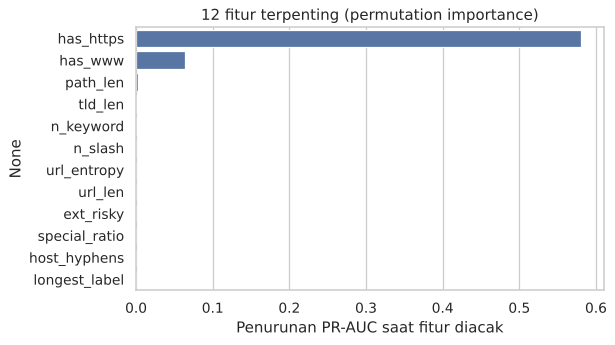

In [13]:
# Permutation importance pada test set
rs = np.random.RandomState(SEED).choice(len(X_te), 15000, replace=False)
pi = permutation_importance(final, X_te.iloc[rs], y_te[rs], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FITUR).sort_values(ascending=False).head(12)
print(imp.head(6).round(4).to_string())
plt.figure(figsize=(7, 4))
sns.barplot(x=imp.values, y=imp.index, color="#4C72B0")
plt.xlabel("Penurunan PR-AUC saat fitur diacak"); plt.title("12 fitur terpenting (permutation importance)")
plt.tight_layout(); plt.show()

**Interpretasi:** `has_https` mendominasi (penurunan PR-AUC 0,58 saat diacak), disusul `has_www` (0,06). Fitur lain berkontribusi jauh lebih kecil (≤ 0,002). Ini konsisten dengan audit dan ablasi.

## 14. Analisis Error

In [14]:
# Analisis error (URL ditampilkan 'defanged' agar aman)
def defang(u):
    return u.replace("http", "hxxp").replace(".", "[.]")[:110]

fn_idx = np.where((pred_final == 0) & (y_te == 1))[0]
fp_idx = np.where((pred_final == 1) & (y_te == 0))[0]
rs = np.random.RandomState(1)
print(f"False Negative (phishing lolos): {len(fn_idx):,} | False Positive (URL aman terblokir): {len(fp_idx):,}\n")
print("Contoh False Negative:")
for i in rs.choice(fn_idx, 6, replace=False):
    print(f"  p={p_final[i]:.3f}  {defang(u_te[i])}")
print("\nContoh False Positive:")
for i in rs.choice(fp_idx, 6, replace=False):
    print(f"  p={p_final[i]:.3f}  {defang(u_te[i])}")

# Domain apa yang paling sering muncul pada FN? (indikasi phishing yang dihosting di platform sah)
dom_te = groups[idx_te]
print("\nDomain terbanyak pada False Negative:")
print(pd.Series(dom_te[fn_idx]).value_counts().head(8).to_string())

False Negative (phishing lolos): 544 | False Positive (URL aman terblokir): 59

Contoh False Negative:
  p=0.604  hxxps://www[.]nmbxeig[.]cn/?ppbtsghj
  p=0.007  hxxps://www[.]velvetjobs[.]com/sign_in?redirect=/ja/jobs/p16098763
  p=0.142  hxxps://www[.]linkbux[.]com/track?pid=LB00002126&amp;mid=58498&amp;url=hxxps://www[.]leroymerlin[.]com[.]br/&a
  p=0.133  hxxps://www[.]playstation[.]com/de-de/explore/ps4/features/playstation-app/?et_cid=em_331923&et_rid=2233052&Li
  p=0.018  hxxps://www[.]languagexperience[.]it/
  p=0.407  hxxps://www[.]ususcm[.]top/go/TrackConfirmAction

Contoh False Positive:
  p=0.959  hxxps://editor[.]altervista[.]org/
  p=0.995  hxxps://jobsearchtech[.]about[.]com/library/weekly/aa083099[.]htm
  p=0.997  hxxps://porting-unix-to-the-386[.]jolix[.]com/
  p=0.918  hxxps://mathworld[.]wolfram[.]com/topics/History[.]html
  p=0.964  hxxps://mathforum[.]org/kb/forumindex[.]jspa
  p=0.987  hxxps://www3[.]cs[.]stonybrook[.]edu/~skiena/214/lectures/

Domain terbanyak pa

**Interpretasi:** *False negative* hampir semuanya berawalan `https://www.`, pola yang dianggap aman oleh model; sebagian lain phishing di platform sah (mis. cakeresume.com dan flipsnack.com), yang tidak bisa dibedakan hanya dari teks URL. *False positive* umumnya situs sah **tanpa** `www` (situs akademik atau situs lama).

## 15. Penyimpanan Model & Fungsi Prediksi

In [15]:
# Simpan model + metadata, lalu fungsi prediksi untuk aplikasi
artefak = {"model": final, "fitur": FITUR, "threshold": THR, "target_recall": TARGET_RECALL, "seed": SEED}
joblib.dump(artefak, "phishing_url_hgb_model.pkl", compress=3)
print("Tersimpan: phishing_url_hgb_model.pkl ({:.2f} MB)".format(os.path.getsize("phishing_url_hgb_model.pkl")/1e6))

def prediksi_url(url, artefak=artefak):
    f = pd.DataFrame([ekstrak_satu(url)], columns=artefak["fitur"], dtype="float32")
    p = float(artefak["model"].predict_proba(f)[:, 1][0])
    thr = artefak["threshold"]
    tingkat = "TINGGI (blokir)" if p >= thr else ("WASPADA" if p >= thr / 2 else "RENDAH")
    r = f.iloc[0]
    alasan = []
    if r.host_is_ip: alasan.append("domain berupa alamat IP")
    if r.n_keyword >= 2: alasan.append("banyak kata sensitif (login/verify/...)")
    if r.host_hyphens >= 2: alasan.append("banyak tanda '-' pada domain")
    if r.n_subdomain >= 3: alasan.append("subdomain bertingkat")
    if r.has_shortener: alasan.append("memakai layanan pemendek URL")
    if r.has_punycode: alasan.append("domain punycode (xn--)")
    if r.n_at: alasan.append("mengandung '@'")
    if r.url_len > 100: alasan.append("URL sangat panjang")
    return {"probabilitas_phishing": round(p, 3), "tingkat_risiko": tingkat, "indikator": alasan or ["-"]}

contoh = ["https://www.wikipedia.org/wiki/Keamanan_komputer",
          "http://192.168.10.5/secure-login/verify-account.php?id=1",
          "http://paypal-secure-update.example.com/webscr/login?confirm=1",
          "https://www.github.com/"]
for u in contoh:
    print(defang(u)); print("   ->", prediksi_url(u))

Tersimpan: phishing_url_hgb_model.pkl (0.21 MB)
hxxps://www[.]wikipedia[.]org/wiki/Keamanan_komputer
   -> {'probabilitas_phishing': 0.001, 'tingkat_risiko': 'RENDAH', 'indikator': ['-']}
hxxp://192[.]168[.]10[.]5/secure-login/verify-account[.]php?id=1
   -> {'probabilitas_phishing': 1.0, 'tingkat_risiko': 'TINGGI (blokir)', 'indikator': ['domain berupa alamat IP', 'banyak kata sensitif (login/verify/...)']}
hxxp://paypal-secure-update[.]example[.]com/webscr/login?confirm=1
   -> {'probabilitas_phishing': 1.0, 'tingkat_risiko': 'TINGGI (blokir)', 'indikator': ['banyak kata sensitif (login/verify/...)', "banyak tanda '-' pada domain"]}
hxxps://www[.]github[.]com/
   -> {'probabilitas_phishing': 0.02, 'tingkat_risiko': 'RENDAH', 'indikator': ['-']}


**Interpretasi:** Model berukuran 0,21 MB dan disimpan bersama daftar fitur serta ambang. URL Wikipedia dan GitHub dinilai berisiko rendah, sedangkan dua URL contoh dengan kata sensitif (login, verify, webscr) ditandai tinggi lengkap dengan indikator alasannya, sehingga mudah ditampilkan kepada pengguna.

## 16. Ringkasan Hasil

In [16]:
# Ringkasan hasil
r = tabel_test.iloc[1]
print(f"HASIL AKHIR (test set per domain, ambang {THR:.3f})")
print(f"  PR-AUC   : {r['PR-AUC']:.3f}")
print(f"  Recall   : {r['Recall']:.3f}  (target {TARGET_RECALL:.2f})")
print(f"  Precision: {r['Precision']:.3f}")
print(f"  F1       : {r['F1']:.3f}")
print(f"  Phishing lolos (FN)  : {fn:,} dari {tp+fn:,}")
print(f"  URL aman terblokir (FP): {fp:,} dari {tn+fp:,}")
sh = abl.set_index("Model")
print(f"\nKetergantungan pada https/www (PR-AUC): semua fitur {sh.loc['Semua fitur','PR-AUC']:.3f} | "
      f"tanpa keduanya {sh.loc['Tanpa has_https & has_www','PR-AUC']:.3f} | "
      f"hanya keduanya {sh.loc['HANYA has_https & has_www','PR-AUC']:.3f}")

HASIL AKHIR (test set per domain, ambang 0.880)
  PR-AUC   : 0.997
  Recall   : 0.977  (target 0.98)
  Precision: 0.997
  F1       : 0.987
  Phishing lolos (FN)  : 544 dari 24,002
  URL aman terblokir (FP): 59 dari 72,029

Ketergantungan pada https/www (PR-AUC): semua fitur 0.997 | tanpa keduanya 0.971 | hanya keduanya 0.985


## 17. Kesimpulan, Keterbatasan & Relevansi CIA Triad

**Kesimpulan:** pada dataset ini model mencapai PR-AUC 0,997 dengan recall 0,977 dan precision 0,997 pada test per domain. Namun, hasil ini sangat dipengaruhi pola `https`/`www`, sehingga harus dibaca sebagai performa pada dataset ini, bukan jaminan di dunia nyata.

### Keterbatasan
1. **Bias sumber dataset** (bagian 5, 12, 13): generalisasi ke phishing ber-`https://www.` belum terbukti.
2. **Hanya fitur leksikal:** isi halaman, sertifikat SSL, usia domain, dan reputasi tidak diperiksa. Phishing di platform sah sulit ditangkap.
3. **Domain terdaftar diperkirakan dengan aturan sederhana** (bukan *public suffix list*).
4. **Pergeseran waktu:** pola phishing berubah, sehingga model perlu dilatih ulang dan dipantau berkala.
5. **Peringatan palsu** meningkat pada prevalensi rendah; sediakan mekanisme umpan balik pengguna.

### Relevansi CIA Triad
- **Confidentiality:** phishing mencuri kredensial dan data pribadi; penyaringan URL di awal mengurangi peluang korban memasukkan data.
- **Integrity:** URL palsu dipakai untuk memanipulasi alur transaksi atau form ganti kata sandi.
- **Peran sistem:** lapisan penyaring dini yang melengkapi, bukan menggantikan, edukasi pengguna, MFA, dan pemeriksaan reputasi.

### Langkah lanjutan
1. Validasi pada data dari sumber lain dan seragamkan skema/`www` saat pelatihan.
2. Tambahkan fitur non-leksikal yang aman (usia domain, DNS) bila memungkinkan.
3. Bungkus `prediksi_url` dalam aplikasi web dengan tiga tingkat risiko dan penjelasan indikator.